# Week 2 – Data Preparation and Baseline

**Project:** Predicting early (< 30 days) hospital readmission of diabetic patients – Diabetes 130-US Hospitals (UCI).
**Plan followed:** [`Week_1/project_specification.pdf`](../Week_1/project_specification.pdf), sections 5–7.

Week 2 objectives (from the project timeline) and where they are covered:

| Timeline objective | Section |
| --- | --- |
| Clean and preprocess the dataset | 1, 2, 3, 6 |
| Analyse features, missing values and target distribution | 5 (training patients only) |
| Define training, validation and test sets | 4 |
| Select and implement a baseline model | 7, 8 |
| Evaluate initial performance with appropriate metrics | 9, 10 |

**Deliverables:** clean dataset (`outputs/diabetic_clean.csv.gz` + `outputs/feature_config.json`), baseline implementation (this notebook), initial results (`outputs/baseline_cv_results.csv`, `outputs/report_week1`, report of what has been done).

### Anti-leakage rules applied in this notebook

| Risk | Rule |
| --- | --- |
| Same patient in train and test (16k patients have several encounters) | Split **by patient** (`GroupShuffleSplit` then `StratifiedGroupKFold` on `patient_nbr`), checked by assertions. |
| Statistics computed on data used for evaluation | Before the split, only **row-wise** operations (each row is transformed using its own values only). Every learned step (imputation, scaling, one-hot categories, rare-level grouping, class weights) lives **inside a scikit-learn `Pipeline`**, refitted on each training fold. |
| Feature decisions driven by the test set | Missing-rate and constant-column decisions, and all descriptive analysis of this week, use **training patients only**. |
| Test set reused for model choice | The test set is **not used at all** this week it will be evaluated once, in week 4. Model comparison uses 5-fold cross-validation on the training patients. |
| Identifiers / target in the features | `encounter_id`, `patient_nbr` and `readmitted` are excluded from `X`; `patient_nbr` is only used as a group key. |
| Outcome not observable | Encounters ending with death or hospice are removed (section 5): such patients cannot be readmitted in a normal way. |

> Note: the week-1 EDA notebook explored the whole file, including future test patients. This is acceptable for a first look, but every decision taken here is re-derived from the training patients only.

In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn import set_config
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42           
TEST_SIZE = 0.20    
N_FOLDS = 5         
TOP_FRACTION = 0.20 # follow-up capacity: the 20 % most at-risk encounters are flagged

set_config(display="diagram")
pd.set_option("display.max_columns", 60)

# Chart style: thin marks, recessive axes, fixed colour order
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ad", "axes.grid": True, "grid.color": "#e6e5e0",
    "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.titleweight": "bold",
    "axes.titlesize": 11, "axes.labelcolor": GRAY, "xtick.color": GRAY, "ytick.color": GRAY,
})

# To locate the directory no matter the working folder
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "diabetic_data.csv").is_file())
OUT_DIR = ROOT / "Week_2" / "outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("Repository root:", ROOT)

Repository root: c:\Users\noepa\Documents\A4\Projet Machine Learning\ml_project_esilv


## 1. Load the raw data and define the cohort

The file is read with `keep_default_na=False` so that the raw markers (`?`, `None`) stay visible; they are interpreted explicitly in section 3.

**Cohort.** Encounters whose discharge disposition means the patient **died or went to a hospice** are removed, because a readmission cannot be observed normally for them. From IDS_mapping.csv: 11 *Expired*, 13 *Hospice / home*, 14 *Hospice / medical facility*, 19–21 *Expired … hospice*. This filter only uses the row's own discharge code (never the target), so it is safe to apply before the split.

In [2]:
raw = pd.read_csv(ROOT / "diabetic_data.csv", keep_default_na=False, low_memory=False,
                  dtype={"payer_code": "object"})
print(f"Raw data: {raw.shape[0]:,} encounters, {raw.shape[1]} columns, {raw['patient_nbr'].nunique():,} patients")

EXCLUDED_DISCHARGE = {11: "Expired", 13: "Hospice / home", 14: "Hospice / medical facility",
                      19: "Expired at home (hospice)", 20: "Expired in a medical facility (hospice)",
                      21: "Expired, place unknown (hospice)"}
excluded = raw["discharge_disposition_id"].isin(list(EXCLUDED_DISCHARGE))
display(raw.loc[excluded, "discharge_disposition_id"].map(EXCLUDED_DISCHARGE)
        .value_counts().rename("Encounters removed").to_frame())

cohort = raw.loc[~excluded].reset_index(drop=True)
print(f"Cohort: {len(cohort):,} encounters ({excluded.sum():,} removed), {cohort['patient_nbr'].nunique():,} patients")

Raw data: 101,766 encounters, 50 columns, 71,518 patients


,Encounters removed
discharge_disposition_id,
Expired,1642
Hospice / home,399
Hospice / medical facility,372
Expired at home (hospice),8
Expired in a medical facility (hospice),2


Cohort: 99,343 encounters (2,423 removed), 69,990 patients


## 2. Binary target

`y = 1` if `readmitted == "<30"`, else `0` (`>30` and `NO` are grouped: a readmission after 30 days is not an early readmission). The original column is then removed from the features.

In [4]:
assert set(cohort["readmitted"].unique()) == {"<30", ">30", "NO"}
cohort["target"] = (cohort["readmitted"] == "<30").astype(int)
print("Target defined. Distribution analysed on train in section 5")

Target defined. Distribution analysed on train in section 5


## 3. Row-wise cleaning 

Every transformation below uses only the values of the row itself, with fixed rules decided from the data documentation, so applying them to the whole cohort before splitting cannot leak information and we do not learn any statistics:

| Raw issue | Transformation |
| --- | --- |
| `?` in categorical fields | missing (`NaN`); turned into an explicit `Unknown` category later, inside the pipeline |
| `gender = Unknown/Invalid` (3 rows) |  missing |
| `age` stored as `[70-80)` |  numeric midpoint (`75`), keeps the order of the age groups |
| `diag_1..3`: ~700 ICD-9 codes each |  9 clinical groups (Strack et al., 2014)  |
| `max_glu_serum`, `A1Cresult` = `None` |  `NotMeasured` (UCI: test not taken — informative, not a missing value) |
| `admission_type_id`, `discharge_disposition_id`, `admission_source_id` |  strings: they are codes, not quantities |

Imputation, scaling, rare-category grouping and dropping columns based on their statistics are **not** done here (see sections 5 and 6).

In [ ]:
MEDICATIONS = [
    "metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride", "acetohexamide",
    "glipizide", "glyburide", "tolbutamide", "pioglitazone", "rosiglitazone", "acarbose", "miglitol",
    "troglitazone", "tolazamide", "examide", "citoglipton", "insulin", "glyburide-metformin",
    "glipizide-metformin", "glimepiride-pioglitazone", "metformin-rosiglitazone", "metformin-pioglitazone",
]
ID_CODES = ["admission_type_id", "discharge_disposition_id", "admission_source_id"]


def icd9_group(code):
    if pd.isna(code):
        return "Missing"
    if code[0] in "VE":                     
        return "Other"
    value = float(code)
    if 250 <= value < 251:
        return "Diabetes"
    if 390 <= value < 460 or int(value) == 785:
        return "Circulatory"
    if 460 <= value < 520 or int(value) == 786:
        return "Respiratory"
    if 520 <= value < 580 or int(value) == 787:
        return "Digestive"
    if 580 <= value < 630 or int(value) == 788:
        return "Genitourinary"
    if 710 <= value < 740:
        return "Musculoskeletal"
    if 800 <= value < 1000:
        return "Injury"
    if 140 <= value < 240:
        return "Neoplasms"
    return "Other"


def clean_rowwise(df):
    out = df.copy()
    out = out.replace("?", np.nan)
    out["gender"] = out["gender"].replace("Unknown/Invalid", np.nan)
    out["age_years"] = out["age"].str.extract(r"\[(\d+)-(\d+)\)").astype(int).mean(axis=1)
    for k in (1, 2, 3):
        out[f"diag_{k}_group"] = out[f"diag_{k}"].map(icd9_group)
    for lab in ("max_glu_serum", "A1Cresult"):
        out[lab] = out[lab].replace("None", "NotMeasured")
    for col in ID_CODES:
        out[col] = out[col].astype(str)
    return out.drop(columns=["age", "diag_1", "diag_2", "diag_3"])


clean = clean_rowwise(cohort)
display(clean[["age_years", "diag_1_group", "diag_2_group", "diag_3_group",
               "A1Cresult", "max_glu_serum", "discharge_disposition_id"]].head())

,age_years,diag_1_group,diag_2_group,diag_3_group,A1Cresult,max_glu_serum,discharge_disposition_id
0,5.0,Diabetes,Missing,Missing,NotMeasured,NotMeasured,25
1,15.0,Other,Diabetes,Other,NotMeasured,NotMeasured,1
2,25.0,Other,Diabetes,Other,NotMeasured,NotMeasured,1
3,35.0,Other,Diabetes,Circulatory,NotMeasured,NotMeasured,1
4,45.0,Neoplasms,Neoplasms,Diabetes,NotMeasured,NotMeasured,1


## 4. Training / validation / test sets (split by patient)


1. **Test set** GroupShuffleSplit keeps **20 % of the patients** aside. All encounters of a patient go to the same side, otherwise the model could recognise a patient it has already seen.
2. **Validation** – on the remaining 80 %, StratifiedGroupKFold (5 folds, grouped by patient, stratified on the target) gives 5 train/validation pairs. Cross-validation is used instead of a single validation split: with only ~11 % positives, one split would give noisy estimates, and the folds also give a standard deviation.

The test set is set aside now and not looked at (not even its target rate) until week 4.

In [6]:
gss = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=SEED)
train_idx, test_idx = next(gss.split(clean, groups=clean["patient_nbr"]))
train = clean.iloc[train_idx].reset_index(drop=True)
test = clean.iloc[test_idx].reset_index(drop=True)          # set aside until week 4

# Fold assignment on the training patients
sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
train["fold"] = -1
for fold, (_, val_idx) in enumerate(sgkf.split(train, train["target"], groups=train["patient_nbr"])):
    train.loc[val_idx, "fold"] = fold

assert set(train["patient_nbr"]).isdisjoint(test["patient_nbr"]), "patient in train AND test"
assert (train["fold"] >= 0).all()
assert train.groupby("patient_nbr")["fold"].nunique().max() == 1, "patient in several folds"
assert len(train) + len(test) == len(clean)

split_summary = pd.DataFrame({
    "Encounters": [len(train), len(test)],
    "Patients": [train["patient_nbr"].nunique(), test["patient_nbr"].nunique()],
}, index=["train (CV)", "test (held out)"])
split_summary["Share of encounters (%)"] = (split_summary["Encounters"] / len(clean) * 100).round(1)
display(split_summary)

fold_summary = train.groupby("fold").agg(encounters=("target", "size"), patients=("patient_nbr", "nunique"),
                                         positives=("target", "sum"))
fold_summary["positive rate (%)"] = (fold_summary["positives"] / fold_summary["encounters"] * 100).round(2)
display(fold_summary)
print("All checks passed: no patient is shared between train/test or between two validation folds.")

,Encounters,Patients,Share of encounters (%)
train (CV),79541,55992,80.1
test (held out),19802,13998,19.9


,encounters,patients,positives,positive rate (%)
fold,,,,
0,15908,11174,1819,11.43
1,15908,11167,1819,11.43
2,15908,11231,1820,11.44
3,15909,11231,1820,11.44
4,15908,11189,1820,11.44


All checks passed: no patient is shared between train/test or between two validation folds.


## 5. Analysis on training patients only

From here on, every statistic is computed on `train` only.

### 5.1 Target distribution

,Encounters,Share (%)
readmitted,,
NO,42031,52.84
>30,28412,35.72
<30,9098,11.44


Positive class (<30 days): 9,098 / 79,541 = 11.44%  -> imbalance ratio about 1:8


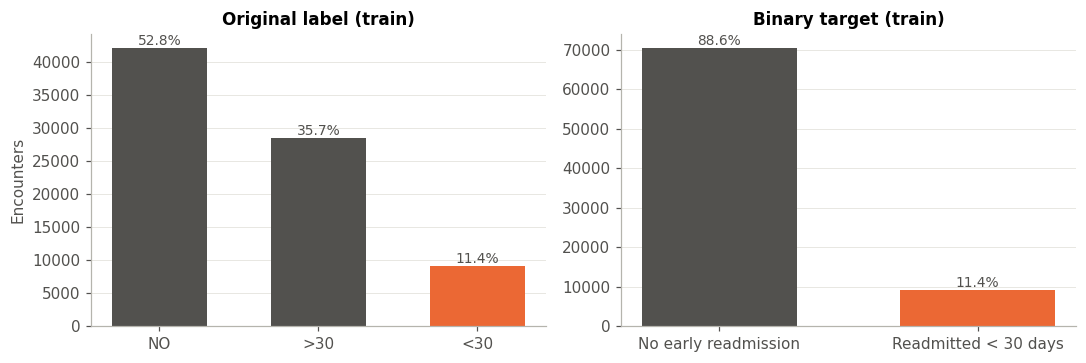

In [7]:
orig = train["readmitted"].value_counts().reindex(["NO", ">30", "<30"])
binary = train["target"].value_counts().reindex([0, 1])
prevalence = train["target"].mean()
display(pd.DataFrame({"Encounters": orig, "Share (%)": (orig / len(train) * 100).round(2)}))
print(f"Positive class (<30 days): {binary[1]:,} / {len(train):,} = {prevalence:.2%}  "
      f"-> imbalance ratio about 1:{binary[0] / binary[1]:.0f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].bar(orig.index, orig.values, color=[GRAY, GRAY, ORANGE], width=0.6)
axes[0].set_title("Original label (train)")
axes[0].set_ylabel("Encounters")
axes[1].bar(["No early readmission", "Readmitted < 30 days"], binary.values, color=[GRAY, ORANGE], width=0.6)
axes[1].set_title("Binary target (train)")
for ax, values in zip(axes, (orig.values, binary.values)):
    for x, v in enumerate(values):
        ax.text(x, v, f"{v / len(train):.1%}", ha="center", va="bottom", fontsize=9, color=GRAY)
    ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

With about 11 % positives, a model that always predicts "no readmission" already reaches ~89 % accuracy. Accuracy is therefore not used to compare models: the main metric is **PR-AUC** (average precision), whose chance level equals the prevalence.

### 5.2 Missing values

,Missing in train (%)
weight,96.90
medical_specialty,48.92
payer_code,39.68
race,2.28
gender,0.00


Not measured (informative category, not missing): {'max_glu_serum': '94.8%', 'A1Cresult': '83.0%'}


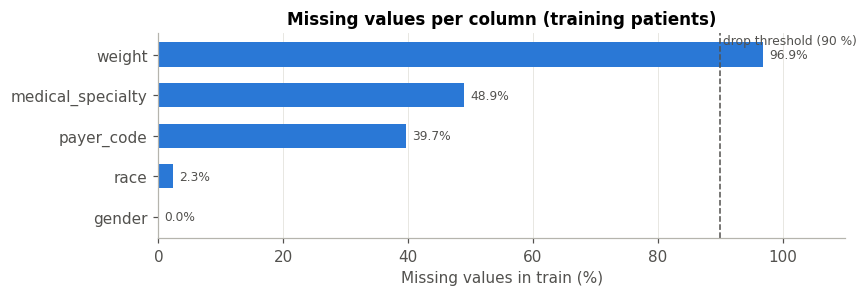

In [8]:
missing = train.isna().mean().mul(100).sort_values(ascending=False)
missing = missing[missing > 0]
not_measured = {lab: train[lab].eq("NotMeasured").mean() * 100 for lab in ("max_glu_serum", "A1Cresult")}
display(missing.round(2).rename("Missing in train (%)").to_frame())
print("Not measured (informative category, not missing):", {k: f"{v:.1f}%" for k, v in not_measured.items()})

fig, ax = plt.subplots(figsize=(8, 2.8))
ax.barh(missing.index[::-1], missing.values[::-1], color=BLUE, height=0.6)
ax.axvline(90, color=GRAY, linestyle="--", linewidth=1)
ax.text(90.5, len(missing) - 0.5, "drop threshold (90 %)", color=GRAY, fontsize=8, va="top")
for y, v in enumerate(missing.values[::-1]):
    ax.text(v + 1, y, f"{v:.1f}%", va="center", fontsize=8, color=GRAY)
ax.set_xlim(0, 110)
ax.set_xlabel("Missing values in train (%)")
ax.set_title("Missing values per column (training patients)")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

Decisions (taken from the training rates only):

* **> 90 % missing → drop.** Only `weight` is concerned: imputing a variable that is almost never observed would mostly create noise.
* `payer_code` and `medical_specialty` (~40–50 % missing) are **kept**, with missing values turned into an explicit `Unknown` category: the absence of the information may itself be related to the type of stay, and the logistic regression can learn a separate coefficient for it.
* `race`, the diagnosis groups and `gender` have few missing values and turn into `Unknown` category as well.
* There are no missing values in the numerical columns. A median imputer is still put in the pipeline so that it would be learned on the training fold if new data had gaps.

### 5.3 Constant columns and cardinality of categorical variables

In [9]:
NUMERIC = ["age_years", "time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
           "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]
CANDIDATE_CATEGORICAL = (["race", "gender", "payer_code", "medical_specialty", *ID_CODES,
                          "diag_1_group", "diag_2_group", "diag_3_group", "max_glu_serum", "A1Cresult",
                          "change", "diabetesMed"] + MEDICATIONS)

MISSING_THRESHOLD = 0.90
too_missing = [c for c in train.columns if train[c].isna().mean() > MISSING_THRESHOLD]
constant = [c for c in CANDIDATE_CATEGORICAL + NUMERIC if train[c].nunique(dropna=False) == 1]

card = pd.DataFrame({
    "levels in train": train[CANDIDATE_CATEGORICAL].nunique(dropna=False),
    "levels with < 50 encounters": train[CANDIDATE_CATEGORICAL].apply(lambda s: (s.value_counts(dropna=False) < 50).sum()),
    "most frequent level (%)": train[CANDIDATE_CATEGORICAL].apply(lambda s: s.value_counts(normalize=True, dropna=False).iloc[0] * 100).round(2),
}).sort_values("levels in train", ascending=False)
print("Dropped – more than 90 % missing:", too_missing)
print("Dropped – constant in train:", constant)
display(card.head(12))

Dropped – more than 90 % missing: ['weight']
Dropped – constant in train: ['examide', 'citoglipton', 'glimepiride-pioglitazone']


,levels in train,levels with < 50 encounters,most frequent level (%)
medical_specialty,73,40,48.92
discharge_disposition_id,21,7,60.60
payer_code,18,2,39.68
admission_source_id,17,7,56.19
diag_1_group,10,1,29.84
diag_3_group,10,0,29.85
diag_2_group,10,0,31.25
admission_type_id,8,2,52.58
race,6,0,74.60
insulin,4,0,46.55


* Columns with a single value in the training data carry no information and are dropped (`examide`, `citoglipton`, and `glimepiride-pioglitazone`, which has only one non-`No` encounter in the full file, not among the training patients).

* `medical_specialty` (~70 levels) and the admission/discharge codes have many rare levels. Rather than grouping them by hand on the whole data, the `OneHotEncoder` uses `min_frequency=50`: levels seen fewer than 50 times **in the training fold** are merged into one `infrequent` column, and unseen levels at validation time are mapped to it (`handle_unknown="infrequent_if_exist"`). The grouping is therefore re-learned in every fold.

* Several medications are almost always `No`. They are kept for the baseline; the feature selection of week 3 (filter / wrapper / embedded) will decide whether they are useful.

### 5.4 Features vs. target (descriptive, training patients)

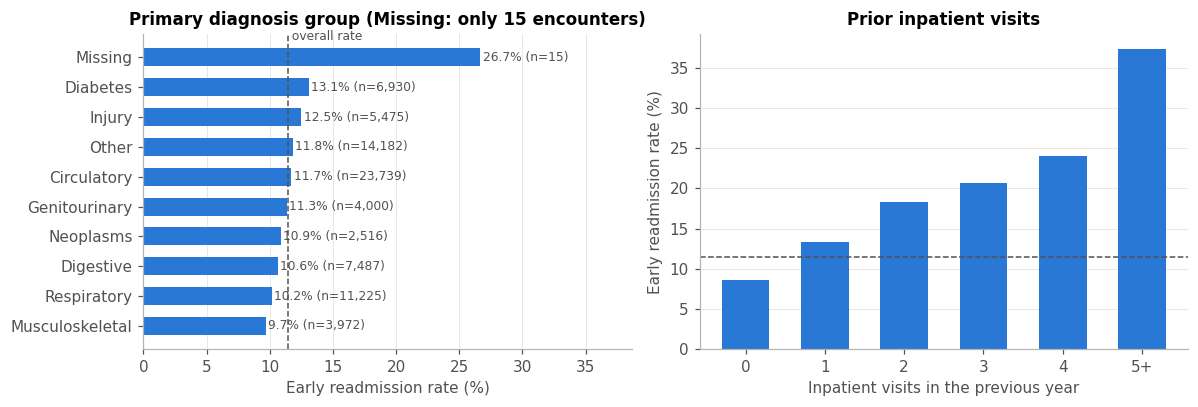

,mean (y=0),mean (y=1),relative difference (%)
number_inpatient,0.56,1.22,119.2
number_emergency,0.18,0.35,98.2
number_outpatient,0.36,0.44,22.1
time_in_hospital,4.33,4.76,10.0
num_medications,15.87,16.89,6.4
number_diagnoses,7.36,7.69,4.5
num_lab_procedures,42.75,44.29,3.6
age_years,65.62,66.83,1.8
num_procedures,1.34,1.26,-5.9


In [10]:
diag_rates = (train.groupby("diag_1_group")["target"].agg(["size", "mean"])
              .rename(columns={"size": "encounters", "mean": "rate"}).sort_values("rate"))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
ax.barh(diag_rates.index, diag_rates["rate"] * 100, color=BLUE, height=0.6)
ax.axvline(prevalence * 100, color=GRAY, linestyle="--", linewidth=1)
ax.text(prevalence * 100, len(diag_rates) - 0.4, " overall rate", color=GRAY, fontsize=8)
for y, (rate, n) in enumerate(zip(diag_rates["rate"], diag_rates["encounters"])):
    ax.text(rate * 100 + 0.2, y, f"{rate:.1%} (n={n:,})", va="center", fontsize=8, color=GRAY)
ax.set_xlim(0, diag_rates["rate"].max() * 100 * 1.45)
ax.set_xlabel("Early readmission rate (%)")
ax.set_title("Primary diagnosis group (Missing: only 15 encounters)")
ax.grid(axis="y", visible=False)

inp = train.assign(prior_inpatient=train["number_inpatient"].clip(upper=5)).groupby("prior_inpatient")["target"].mean()
ax = axes[1]
ax.bar([str(i) if i < 5 else "5+" for i in inp.index], inp.values * 100, color=BLUE, width=0.6)
ax.axhline(prevalence * 100, color=GRAY, linestyle="--", linewidth=1)
ax.set_xlabel("Inpatient visits in the previous year")
ax.set_ylabel("Early readmission rate (%)")
ax.set_title("Prior inpatient visits")
ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

num_by_class = train.groupby("target")[NUMERIC].mean().T
num_by_class.columns = ["mean (y=0)", "mean (y=1)"]
num_by_class["relative difference (%)"] = ((num_by_class["mean (y=1)"] / num_by_class["mean (y=0)"] - 1) * 100).round(1)
display(num_by_class.round(2).sort_values("relative difference (%)", ascending=False))

The previous-year utilisation counts (`number_inpatient`, `number_emergency`, `number_outpatient`) show the largest differences between the two classes, and the readmission rate grows steadily with the number of prior inpatient stays. The diagnosis groups show smaller differences. These are univariate, non-causal observations; the variables are correlated and patients are repeated. They are not used to select features at this stage (feature selection is done in week 3 inside the cross-validation).

## 6. Clean dataset and feature configuration

Final feature set for the baseline: 9 numerical + all remaining categorical variables. The saved file contains the cleaned columns, the target, the patient id (group key) and the `split` / `fold` assignment, so that weeks 3 and 4 reuse **exactly** the same split.

In [11]:
DROPPED = {c: "more than 90% missing in train" for c in too_missing}
DROPPED.update({c: "constant in train" for c in constant})
DROPPED.update({"encounter_id": "identifier", "patient_nbr": "identifier (used only as a group key)",
                "readmitted": "original target"})
CATEGORICAL = [c for c in CANDIDATE_CATEGORICAL if c not in DROPPED]
FEATURES = NUMERIC + CATEGORICAL
assert not {"encounter_id", "patient_nbr", "readmitted", "target", "fold"} & set(FEATURES)

# object dtype + np.nan for categorical columns (what SimpleImputer/OneHotEncoder expect)
for df in (train, test):
    df[CATEGORICAL] = df[CATEGORICAL].astype(object).where(df[CATEGORICAL].notna(), np.nan)

clean_out = pd.concat([train.assign(split="train"), test.assign(split="test", fold=-1)], ignore_index=True)
clean_out = clean_out[["encounter_id", "patient_nbr", "split", "fold", *FEATURES, "target"]]
clean_out.to_csv(OUT_DIR / "diabetic_clean.csv.gz", index=False)

config = {"seed": SEED, "numeric": NUMERIC, "categorical": CATEGORICAL, "dropped": DROPPED,
          "excluded_discharge_codes": sorted(EXCLUDED_DISCHARGE), "target": "readmitted == '<30'",
          "group": "patient_nbr", "test_size": TEST_SIZE, "n_folds": N_FOLDS}
(OUT_DIR / "feature_config.json").write_text(json.dumps(config, indent=2))

print(f"{len(NUMERIC)} numerical + {len(CATEGORICAL)} categorical = {len(FEATURES)} features")
print(f"Saved {clean_out.shape[0]:,} rows x {clean_out.shape[1]} columns -> outputs/diabetic_clean.csv.gz")
display(pd.Series(DROPPED, name="reason").to_frame("Dropped column – reason"))

X_train, y_train = train[FEATURES], train["target"].to_numpy()
folds = train["fold"].to_numpy()

9 numerical + 34 categorical = 43 features
Saved 99,343 rows x 48 columns -> outputs/diabetic_clean.csv.gz


,Dropped column – reason
weight,more than 90% missing in train
examide,constant in train
citoglipton,constant in train
glimepiride-pioglitazone,constant in train
encounter_id,identifier
patient_nbr,identifier (used only as a group key)
readmitted,original target


## 7. Preprocessing pipeline

All learned preprocessing is inside one `Pipeline`, so that `fit` on a training fold learns the medians, means/standard deviations, the list of categories and the infrequent levels from that fold only, and simply applies them to the validation fold.

* **Numerical:** median imputation → standardisation (needed for a regularised logistic regression, so that the penalty treats all features alike).
* **Categorical:** `Unknown` for missing values → one-hot encoding, rare levels (< 50 in the training fold) merged, unseen levels handled.

In [12]:
numeric_pipe = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
categorical_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50, sparse_output=False)),
])
preprocess = ColumnTransformer([("num", numeric_pipe, NUMERIC), ("cat", categorical_pipe, CATEGORICAL)])
preprocess

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. `

## 8. Baseline models

2 baselines :

1. **Majority class** – `DummyClassifier(strategy="prior")`: always predicts "no readmission" and gives every encounter the same probability (the training prevalence). It shows the floor every metric should be compared to, and why accuracy is misleading here.
2. **Logistic regression (main baseline)** – one-hot + standardisation + `class_weight="balanced"`. It is simple, fast, interpretable (one coefficient per feature) and a standard reference in the literature on this dataset. `class_weight="balanced"` gives positives a weight of about 8, so the model does not ignore the minority class; it changes the probability scale (scores are no longer calibrated probabilities) but not the ranking metrics. Default L2 penalty, `C = 1` (tuning is week-3 work).

In [13]:
models = {
    "Majority class (Dummy)": Pipeline([("prep", preprocess), ("clf", DummyClassifier(strategy="prior"))]),
    "Logistic regression (balanced)": Pipeline([
        ("prep", preprocess),
        ("clf", LogisticRegression(class_weight="balanced", max_iter=3000, random_state=SEED)),
    ]),
}
models["Logistic regression (balanced)"]

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains spa

## 9. Cross-validated evaluation

For each of the 5 folds the **whole pipeline** is cloned, fitted on the 4 training folds and evaluated on the held-out fold. Metrics (spec §7):

| Metric | Why |
| --- | --- |
| **PR-AUC** (average precision) – main metric | Focuses on the positive class; chance level = prevalence (~0.11). |
| ROC-AUC | Comparable with published work on this dataset; chance level = 0.5. |
| Precision / recall @ top 20 % | Operational view: the follow-up team can call the 20 % highest-risk encounters. How many of them are true early readmissions, and what share of all early readmissions is caught? |
| Accuracy, balanced accuracy, precision, recall, F1 at threshold 0.5 | Reported for completeness; they depend on the threshold, which will be tuned later. |

We also report the PR-AUC on the training folds, to detect over-fitting.

In [14]:
def top_fraction_metrics(y_true, scores, fraction=TOP_FRACTION):
    # Flag the `fraction` highest scores; return (precision, recall) of that flagged group.
    k = int(np.ceil(fraction * len(scores)))
    flagged = np.zeros(len(scores), dtype=bool)
    flagged[np.argsort(-scores, kind="stable")[:k]] = True
    true_pos = (flagged & (y_true == 1)).sum()
    return true_pos / k, true_pos / (y_true == 1).sum()


def evaluate_cv(model, X, y, fold_ids):
    rows, oof = [], np.full(len(y), np.nan)
    for fold in np.unique(fold_ids):
        tr, va = fold_ids != fold, fold_ids == fold
        fitted = clone(model)
        start = time.perf_counter()
        fitted.fit(X[tr], y[tr])
        fit_time = time.perf_counter() - start
        p_va = fitted.predict_proba(X[va])[:, 1]
        p_tr = fitted.predict_proba(X[tr])[:, 1]
        oof[va] = p_va
        pred = (p_va >= 0.5).astype(int)
        prec_top, rec_top = top_fraction_metrics(y[va], p_va)
        rows.append({
            "fold": fold,
            "PR-AUC": average_precision_score(y[va], p_va),
            "ROC-AUC": roc_auc_score(y[va], p_va),
            "Precision@20%": prec_top,
            "Recall@20%": rec_top,
            "Accuracy": accuracy_score(y[va], pred),
            "Balanced acc.": balanced_accuracy_score(y[va], pred),
            "Precision@0.5": precision_score(y[va], pred, zero_division=0),
            "Recall@0.5": recall_score(y[va], pred),
            "F1@0.5": f1_score(y[va], pred, zero_division=0),
            "Train PR-AUC": average_precision_score(y[tr], p_tr),
            "Fit time (s)": fit_time,
        })
    return pd.DataFrame(rows).set_index("fold"), oof


cv_results, oof_scores = {}, {}
for name, model in models.items():
    cv_results[name], oof_scores[name] = evaluate_cv(model, X_train, y_train, folds)
    print(f"{name}: done")

display(cv_results["Logistic regression (balanced)"].round(4))

Majority class (Dummy): done
Logistic regression (balanced): done


,PR-AUC,ROC-AUC,Precision@20%,Recall@20%,Accuracy,Balanced acc.,Precision@0.5,Recall@0.5,F1@0.5,Train PR-AUC,Fit time (s)
fold,,,,,,,,,,,
0,0.2139,0.6580,0.2143,0.3749,0.6661,0.6112,0.1800,0.5399,0.2700,0.2202,24.6457
1,0.2113,0.6600,0.2084,0.3645,0.6687,0.6109,0.1805,0.5360,0.2701,0.2211,11.8082
2,0.2176,0.6689,0.2159,0.3775,0.6726,0.6173,0.1847,0.5456,0.2760,0.2203,11.3654
3,0.2159,0.6711,0.2200,0.3846,0.6717,0.6288,0.1900,0.5731,0.2854,0.2200,12.3406
4,0.2134,0.6563,0.2159,0.3775,0.6616,0.6116,0.1792,0.5467,0.2699,0.2212,12.1438


In [15]:
METRICS = ["PR-AUC", "ROC-AUC", "Precision@20%", "Recall@20%", "Accuracy", "Balanced acc.",
           "Precision@0.5", "Recall@0.5", "F1@0.5", "Train PR-AUC"]
summary = pd.concat({name: res[METRICS].agg(["mean", "std"]).T for name, res in cv_results.items()}, axis=1)
summary.to_csv(OUT_DIR / "baseline_cv_results.csv")

pretty = pd.DataFrame({name: [f"{summary.loc[m, (name, 'mean')]:.3f} ± {summary.loc[m, (name, 'std')]:.3f}"
                              for m in METRICS] for name in cv_results}, index=METRICS)
print(f"5-fold CV on training patients (mean ± std). Prevalence = {prevalence:.3f}")
display(pretty)

5-fold CV on training patients (mean ± std). Prevalence = 0.114


,Majority class (Dummy),Logistic regression (balanced)
PR-AUC,0.114 ± 0.000,0.214 ± 0.002
ROC-AUC,0.500 ± 0.000,0.663 ± 0.007
Precision@20%,0.117 ± 0.006,0.215 ± 0.004
Recall@20%,0.204 ± 0.010,0.376 ± 0.007
Accuracy,0.886 ± 0.000,0.668 ± 0.004
Balanced acc.,0.500 ± 0.000,0.616 ± 0.008
Precision@0.5,0.000 ± 0.000,0.183 ± 0.005
Recall@0.5,0.000 ± 0.000,0.548 ± 0.015
F1@0.5,0.000 ± 0.000,0.274 ± 0.007
Train PR-AUC,0.114 ± 0.000,0.221 ± 0.001


### 9.1 Curves and confusion matrix

The curves use the out-of-fold scores (each encounter is scored by the model that did not see it during training).

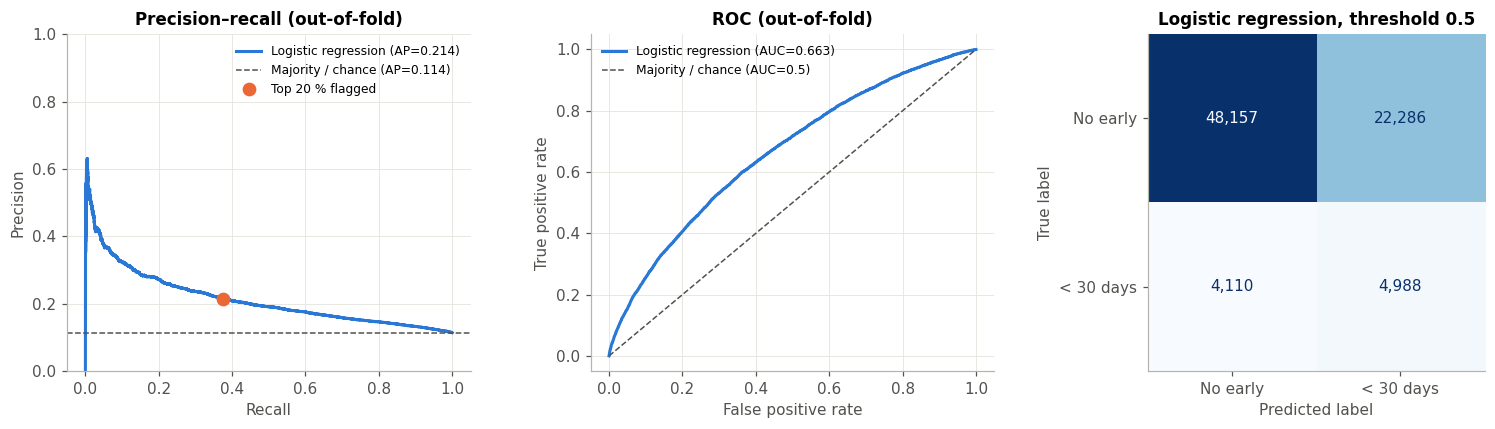

In [16]:
lr_name = "Logistic regression (balanced)"
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

ax = axes[0]
prec, rec, _ = precision_recall_curve(y_train, oof_scores[lr_name])
ax.plot(rec[:-1], prec[:-1], color=BLUE, linewidth=2, label=f"Logistic regression (AP={average_precision_score(y_train, oof_scores[lr_name]):.3f})")
ax.axhline(prevalence, color=GRAY, linestyle="--", linewidth=1, label=f"Majority / chance (AP={prevalence:.3f})")
prec_top, rec_top = top_fraction_metrics(y_train, oof_scores[lr_name])
ax.plot(rec_top, prec_top, "o", color=ORANGE, markersize=8, label="Top 20 % flagged")
ax.set(xlabel="Recall", ylabel="Precision", title="Precision–recall (out-of-fold)", ylim=(0, 1))
ax.legend(fontsize=8, frameon=False)

ax = axes[1]
fpr, tpr, _ = roc_curve(y_train, oof_scores[lr_name])
ax.plot(fpr, tpr, color=BLUE, linewidth=2, label=f"Logistic regression (AUC={roc_auc_score(y_train, oof_scores[lr_name]):.3f})")
ax.plot([0, 1], [0, 1], color=GRAY, linestyle="--", linewidth=1, label="Majority / chance (AUC=0.5)")
ax.set(xlabel="False positive rate", ylabel="True positive rate", title="ROC (out-of-fold)")
ax.legend(fontsize=8, frameon=False)

ConfusionMatrixDisplay.from_predictions(
    y_train, (oof_scores[lr_name] >= 0.5).astype(int), ax=axes[2], colorbar=False, cmap="Blues",
    display_labels=["No early", "< 30 days"], values_format=",")
axes[2].set_title("Logistic regression, threshold 0.5")
axes[2].grid(False)
fig.tight_layout()
plt.show()

### 9.2 Leakage sanity check: shuffled labels

If the pipeline leaked information (e.g. a patient seen in training and validation, or a preprocessing step fitted on the validation fold), a model trained on **randomly permuted labels** could still score above chance. With a clean protocol its PR-AUC must fall back to the prevalence and its ROC-AUC to 0.5.

In [17]:
rng = np.random.default_rng(SEED)
y_shuffled = rng.permutation(y_train)
shuffled_res, _ = evaluate_cv(models[lr_name], X_train, y_shuffled, folds)
print(f"Shuffled labels  -> PR-AUC {shuffled_res['PR-AUC'].mean():.3f} (prevalence {y_shuffled.mean():.3f}), "
      f"ROC-AUC {shuffled_res['ROC-AUC'].mean():.3f}")

Shuffled labels  -> PR-AUC 0.115 (prevalence 0.114), ROC-AUC 0.496


## 10. Interpreting the baseline

The logistic regression is refitted on **all training patients** (still no test data) to inspect its coefficients. Numerical features are standardised, so their coefficients are the change in log-odds for +1 standard deviation; a one-hot coefficient is the change compared with the other levels. They show associations learned by the model, not causal effects.

204 columns after one-hot encoding


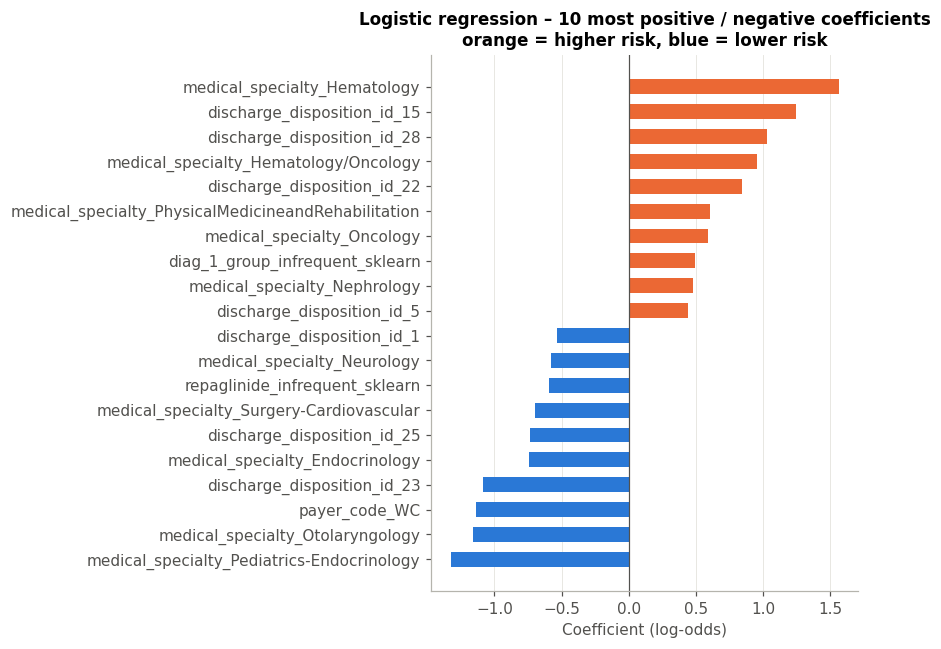

,Coefficient per +1 SD
number_inpatient,0.356
number_diagnoses,0.092
number_emergency,0.082
num_medications,0.052
age_years,0.047
num_lab_procedures,0.017
time_in_hospital,0.007
number_outpatient,0.001
num_procedures,-0.038


In [18]:
lr_full = clone(models[lr_name]).fit(X_train, y_train)
coefs = pd.Series(lr_full.named_steps["clf"].coef_[0],
                  index=lr_full.named_steps["prep"].get_feature_names_out()).rename(lambda s: s.split("__", 1)[1])
print(f"{len(coefs)} columns after one-hot encoding")
top = pd.concat([coefs.nlargest(10), coefs.nsmallest(10)]).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top.values, color=[ORANGE if v > 0 else BLUE for v in top.values], height=0.6)
ax.axvline(0, color=GRAY, linewidth=0.8)
ax.set_xlabel("Coefficient (log-odds)")
ax.set_title("Logistic regression – 10 most positive / negative coefficients\norange = higher risk, blue = lower risk")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

display(coefs[NUMERIC].sort_values(ascending=False).round(3).to_frame("Coefficient per +1 SD"))

## 11. Week 2 results and conclusions

**Data.** After removing deaths and hospice discharges, the cohort has 99,343 encounters from 69,990 patients. 20 % of the patients (19,802 encounters) are kept as the final test set; the 79,541 training encounters (55,992 patients) are split into 5 patient-grouped, stratified folds (positive rate 11.4 % in each fold). The clean dataset has 43 features (9 numerical, 34 categorical); `weight` and three constant medications are dropped.

**Baseline results (5-fold CV, training patients, mean ± std):**

| | Majority class | Logistic regression |
| --- | --- | --- |
| PR-AUC (main metric) | 0.114 | **0.214 ± 0.002** |
| ROC-AUC | 0.500 | 0.663 ± 0.007 |
| Precision @ top 20 % | ≈ 0.11 (random) | 0.215 ± 0.004 |
| Recall @ top 20 % | ≈ 0.20 (random) | 0.376 ± 0.007 |
| Accuracy @ 0.5 | **0.886** | 0.668 |
| Recall @ 0.5 | 0.000 | 0.548 |

* **Accuracy is misleading**, as expected: the majority classifier has the best accuracy (0.886) but never finds a single early readmission. This confirms the choice of PR-AUC as the main metric.
* The logistic regression **almost doubles the PR-AUC** compared with chance (0.214 vs 0.114). In practice, if the follow-up team calls the 20 % highest-risk encounters, about **1 call in 5** reaches a patient who is actually readmitted within 30 days (vs 1 in 9 at random), and **38 %** of all early readmissions are covered.
* The ROC-AUC (0.66) is in the range usually reported for linear models on this dataset: early readmission is hard to predict from administrative data alone. This is the reference that week-3 models must beat.
* The standard deviation over folds is small (0.002 PR-AUC), so differences of a few hundredths between models will be meaningful.
* **No over-fitting:** training PR-AUC (0.221) ≈ validation PR-AUC (0.214). The baseline rather **under-fits** – a linear model cannot use interactions or non-linear effects (e.g. the jump in risk after several prior stays), which motivates tree-based models in week 3.
* **No leakage detected:** with shuffled labels the same pipeline falls back to chance (PR-AUC 0.115 ≈ prevalence, ROC-AUC 0.50).
* The largest coefficients belong to **rare one-hot levels** (some medical specialties and discharge codes, e.g. transfer to rehabilitation or to a psychiatric hospital → higher risk; discharge home → lower risk). They are estimated from few encounters and should be read carefully; among numerical features, the number of prior inpatient visits has by far the largest effect (+0.36 log-odds per standard deviation), followed by the number of diagnoses and prior emergency visits, consistent with section 5.4.

**Limitations of this baseline.** The 0.5 threshold is arbitrary and, because of `class_weight="balanced"`, scores are not calibrated probabilities; the regularisation strength `C` was not tuned; the test set has not been used yet, so all figures above are validation estimates.

**Next steps (week 3, spec §8).** Reuse `outputs/diabetic_clean.csv.gz` and the same folds to: train random forest, gradient boosting and an L1-penalised logistic regression; tune hyperparameters inside the CV; compare filter / wrapper / embedded feature selection (fitted inside each fold); compare everything against the baseline PR-AUC of **0.214**.